# 20. Validación estadística del modelo original (R3)

Este capítulo verifica si el modelo original (ensamble multivista + SECR, capítulo 19) **supera** a los benchmarks
según la definición operativa de la guía (§6.1):

1. su BA media del bucle externo es mayor que la del mejor benchmark y que la de la mejor combinación de cada uno de
   los 7 modelos;
2. al menos tres pruebas de hipótesis distintas rechazan la igualdad, con p ajustado por Holm < 0,05, y al menos una
   es global;
3. el tamaño del efecto no es despreciable: |δ de Cliff| ≥ 0,147.

**Protocolo común (guía §5.3 y §6.2).**

- **Mismas variables.** Los 7 benchmarks (la mejor combinación de balanceo y optimizador de cada modelo, capítulo 13b)
  se reentrenan con las mismas variables crudas que usa el original: las 9 del curso, los códigos OIICS de la lesión,
  NAICS-6, SOC-6 y el empleador. Cada uno con su propio preprocesamiento aprendido dentro del pliegue.
- **Mismas particiones.** Validación externa repetida por establecimiento. La repetición 0 es la partición de los
  capítulos 6 a 13; las repeticiones 1 y 2 usan semillas `seed_for('outer', r)` fijadas antes de correr.
  **Se planeó 5×5 y se recortó a 3×5 (15 pliegues) por tiempo de cómputo**, con el orden de recorte fijado
  antes de ver resultados: las repeticiones 3 y 4 se cortaron para todos los modelos, y Random Forest y Naive
  Bayes (lentos con SMOTE/ADASYN sobre las variables ampliadas) quedaron solo con la repetición 0. KNN, que
  resultó el benchmark más fuerte en la repetición 0, se completó en las 3 repeticiones. Al final de la noche sobró
  tiempo y Random Forest y Naive Bayes también se completaron, así que los 8 modelos tienen las 15 celdas.
- **Mismo presupuesto.** Búsqueda interna de 16 configuraciones con 3 pliegues internos para todos. Los benchmarks
  buscan con su optimizador ganador; el original busca sus hiperparámetros del combinador con TPE.
- **La prueba de octubre a diciembre no se usa** (está bloqueada por código): todas las pruebas son sobre pliegues
  externos. Por eso McNemar y DeLong «sobre el conjunto de prueba» (Figura 4 de la guía) se reemplazan por pruebas
  sobre pliegues que el Cuadro 3 admite: Nadeau–Bengio, Wilcoxon–Holm y la prueba bayesiana con ROPE.

Código: `src/osha_e3/paired.py` (corrida), `src/osha_e3/original_eval.py` (TPE anidado y ablación),
`src/osha_e3/stats_tests.py` (pruebas) y `scripts/analyze_paired.py` (tablas). Las corridas cuestan horas y sus
resultados están versionados en `results/pareado/`; este capítulo los lee.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from osha_e3 import config as C
R = C.RESULTS / 'pareado'
res = json.loads((R / 'resumen.json').read_text(encoding='utf-8'))
f = pd.read_csv(R / 'pliegues.csv')
PRETTY = {'original': 'Original (SECR)', 'knn': 'KNN', 'naive_bayes': 'Naive Bayes', 'logreg': 'Reg. logística',
          'tree': 'Árbol', 'random_forest': 'Random Forest', 'xgboost': 'XGBoost', 'svm': 'SVM'}
print('Celdas (repetición × pliegue) por modelo:', res['n_cells'])
print('Universo con las 15 celdas:', [PRETTY[m] for m in res['universe_25']])

Celdas (repetición × pliegue) por modelo: {'knn': 15, 'logreg': 15, 'naive_bayes': 15, 'original': 15, 'random_forest': 15, 'svm': 15, 'tree': 15, 'xgboost': 15}
Universo con las 15 celdas: ['Original (SECR)', 'SVM', 'Árbol', 'Reg. logística', 'XGBoost', 'KNN', 'Random Forest', 'Naive Bayes']


## 20.1 Tabla resumen

Media ± desviación estándar de la balanced accuracy en los pliegues externos, intervalo bootstrap BCa del 95 % de la
media, otras métricas y tiempos (entrenamiento = búsqueda + reajuste por pliegue; inferencia por caso). La columna
«BA rep. 0» usa solo los 5 pliegues de la repetición 0, que todos los modelos tienen.

In [2]:
s = pd.DataFrame(res['summary_raw'])
tab = pd.DataFrame({
    'Modelo': s.model.map(PRETTY), 'Balanceo': s.balance, 'Optimizador': s.optimizer, 'Pliegues': s.n_pliegues,
    'BA media ± d.e.': [f'{m:.4f} ± {d:.4f}' for m, d in zip(s.ba_mean, s.ba_sd)],
    'IC BCa 95 %': [f'[{a:.4f}, {b:.4f}]' for a, b in zip(s.ba_ci_lo, s.ba_ci_hi)],
    'BA rep. 0': s.ba_rep0_mean.round(4), 'F1 macro': s.f1_mean.round(4), 'AUC macro': s.auc_mean.round(4),
    'Log-loss': s.log_loss_mean.round(4), 'Entrenamiento (s/pliegue)': s.train_s_mean.round(0),
    'Inferencia (ms/caso)': s.ms_case_mean.round(3)})
tab

,Modelo,Balanceo,Optimizador,Pliegues,BA media ± d.e.,IC BCa 95 %,BA rep. 0,F1 macro,AUC macro,Log-loss,Entrenamiento (s/pliegue),Inferencia (ms/caso)
0,Original (SECR),interno (α),bayes (TPE) del combinador,15,0.5912 ± 0.0869,"[0.5413, 0.6281]",0.5910,0.4437,0.8171,0.8428,3085.0,2.468
1,KNN,smote,genetic,15,0.5686 ± 0.0776,"[0.5261, 0.6020]",0.5563,0.3783,0.7635,1.5723,3854.0,12.282
2,SVM,smote,random,15,0.5374 ± 0.0846,"[0.4954, 0.5781]",0.5321,0.4396,0.8002,1.0067,335.0,0.010
3,Reg. logística,adasyn,bayes,15,0.5228 ± 0.1156,"[0.4648, 0.5782]",0.4912,0.4245,0.7757,0.9512,574.0,0.008
4,XGBoost,class_weight,bayes,15,0.4660 ± 0.0522,"[0.4464, 0.4990]",0.4741,0.4331,0.8002,0.8678,260.0,0.109
5,Random Forest,smote,bayes,15,0.4537 ± 0.0470,"[0.4361, 0.4858]",0.4669,0.4291,0.8044,0.8742,3013.0,0.089
6,Naive Bayes,adasyn,genetic,15,0.4260 ± 0.0450,"[0.4087, 0.4563]",0.4349,0.3984,0.7758,1.5071,386.0,0.015
7,Árbol,class_weight,bayes,15,0.4161 ± 0.0830,"[0.3731, 0.4534]",0.4636,0.3507,0.6507,1.1050,20.0,0.008


**Interpretación.** Con las mismas variables y particiones, el modelo original tiene la **BA media más alta**
(0,591 ± 0,087 en 15 pliegues), seguido de KNN (0,569), SVM (0,537) y la logística (0,523). También tiene la mejor
log-loss (0,843 frente a 0,868 a 1,57 de los benchmarks), el mejor AUC macro (0,817) y el mejor F1 macro (0,444).
El ranking cambió respecto al entregable 2: con las variables ampliadas, **KNN pasa a ser el mejor benchmark** (con 9
variables era el quinto) y el árbol cae al último lugar. Los intervalos BCa de la BA del original y de KNN se solapan
ampliamente ([0,541; 0,628] y [0,526; 0,602]). El original tarda 51 min de media por pliegue en entrenar (mediana 40, rango
30–91; nivel 0 + TPE + SECR, columna `train_s`) y 2,5 ms por caso en predecir.

## 20.2 Prueba global: Friedman y diagrama de diferencia crítica

Friedman (con la corrección F de Iman y Davenport) compara todos los modelos a la vez, con los pliegues como bloques
y **el modelo original incluido en el universo**. Si rechaza, Nemenyi indica qué pares difieren: dos modelos cuya
distancia de rangos medios es menor que la diferencia crítica (CD) no se distinguen. Se hace con (a) los modelos que
tienen las 15 celdas (3 repeticiones × 5 pliegues) y (b) los 8 modelos en los 5 pliegues de la repetición 0.

15 pliegues: k = 8, N = 15, χ² = 48.44, p = 2.91e-08; F de Iman-Davenport = 11.99, p = 5.76e-11; CD = 2.711
repetición 0 (5 pliegues): k = 8, N = 5, χ² = 12.33, p = 9.01e-02; F de Iman-Davenport = 2.18, p = 6.77e-02; CD = 4.695


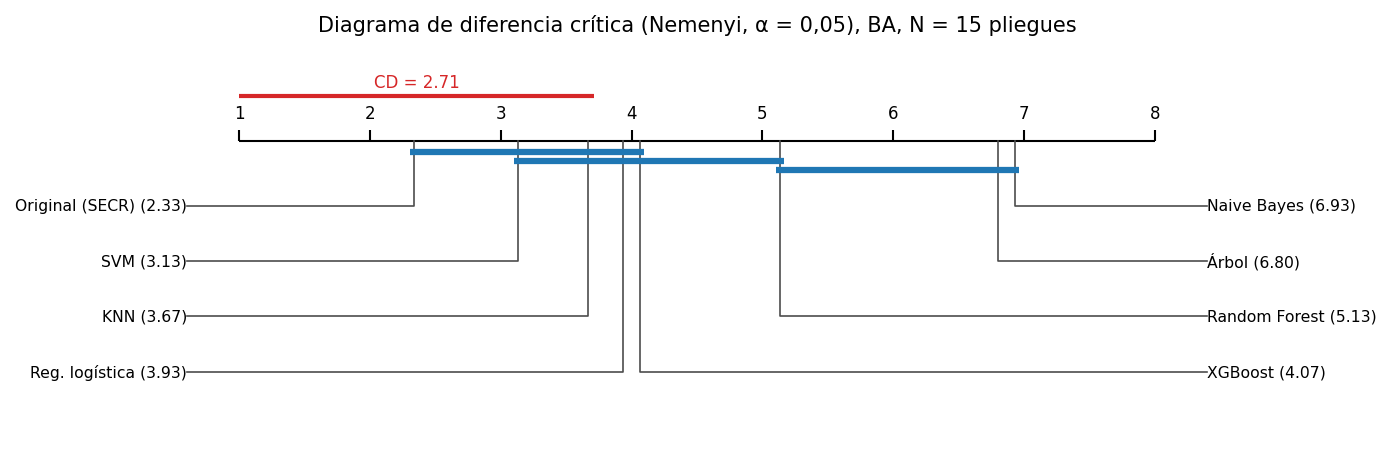

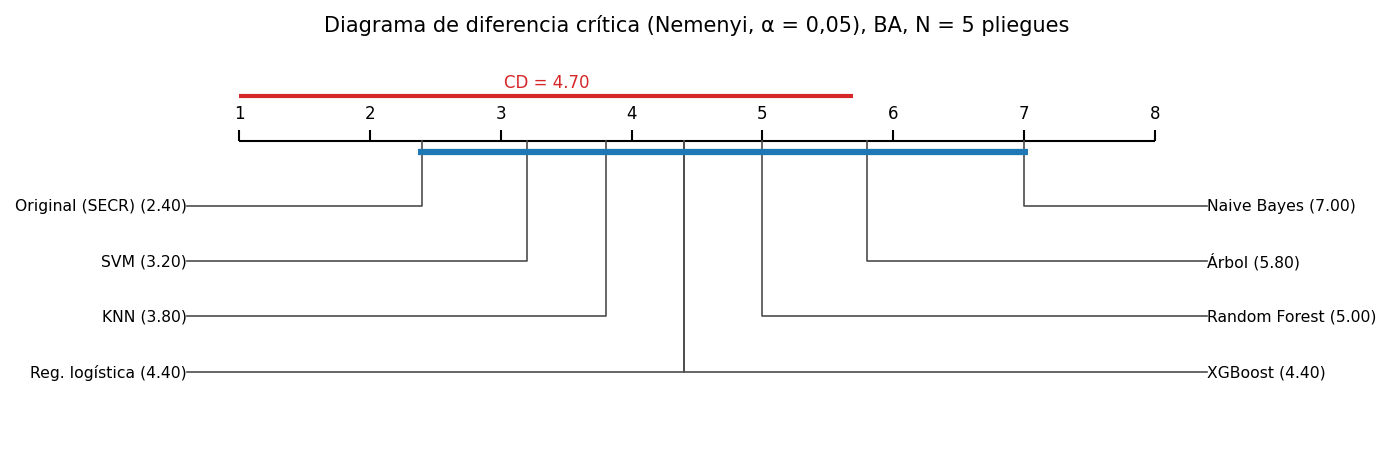

In [3]:
for tag, key, cd in [('15 pliegues', 'friedman25', 'cd25'), ('repetición 0 (5 pliegues)', 'friedman_rep0', 'cd_rep0')]:
    fr = res[key]
    print(f"{tag}: k = {fr['k']}, N = {fr['n_blocks']}, χ² = {fr['chi2']:.2f}, p = {fr['p_value']:.2e}; "
          f"F de Iman-Davenport = {fr['iman_davenport_F']:.2f}, p = {fr['p_value_F']:.2e}; CD = {res[cd]:.3f}")
display(Image('figures/e3_cd_pareado_25.png'))
display(Image('figures/e3_cd_pareado_rep0.png'))

**Interpretación.** Con 15 pliegues y los 8 modelos, Friedman **rechaza** que todos tengan el mismo rango medio
(F de Iman-Davenport = 11,99; p = 6·10⁻¹¹). El original tiene el mejor rango medio (2,33), seguido de SVM (3,13), KNN
(3,67), la logística (3,93), XGBoost (4,07), Random Forest (5,13), el árbol (6,80) y Naive Bayes (6,93). La diferencia
crítica de Nemenyi es 2,71: **el original se separa de Random Forest, el árbol y Naive Bayes, pero no de SVM, KNN, la
logística ni XGBoost**. Con solo los 5 pliegues de la
repetición 0, Friedman no rechaza (p = 0,068): 5 bloques dan muy poca potencia, como ya pasó en el capítulo 13.

## 20.3 Pruebas pareadas frente al mejor benchmark y a cada benchmark

Tabla obligatoria de la guía (§6.3): prueba, hipótesis nula, supuestos verificados, estadístico, p crudo, p ajustado,
tamaño del efecto y conclusión. Las 4 pruebas frecuentistas forman una familia y se ajustan con Holm (4 comparaciones).
La bayesiana no da un p-valor: da probabilidades posteriores de que el original sea peor, equivalente (dentro de la
ROPE de ±0,01 de BA) o mejor.

In [4]:
pd.DataFrame(res['tests'])

,Prueba,H0,Supuestos,Estadístico,p crudo,"p ajustado (Holm, 4)",Efecto,Conclusión
0,"Friedman (Iman-Davenport), universo de 15 plie...",Todos los modelos tienen el mismo rango medio,"bloques = pares (rep., pliegue) independientes...",F = 11.992,5.76e-11,2.30e-10,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",Se rechaza H0
1,Nemenyi post hoc: original vs KNN,Igual rango medio,tras Friedman; CD = 2.711,ΔR = 1.333,8.13e-01,8.13e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
2,t corregida de Nadeau-Bengio: original vs KNN,Diferencia media de BA ≤ 0,normalidad de diferencias (Shapiro p = 0.049);...,t(14) = 0.453,3.29e-01,6.58e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
3,Wilcoxon de rangos con signo: original vs KNN,Mediana de la diferencia ≤ 0,"diferencias simétricas, pareadas por pliegue",W = 84.0,9.38e-02,2.81e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
4,"Bayesiana de rangos con signo (ROPE ±0,01 BA):...",— (probabilidades posteriores),"proceso de Dirichlet, pseudo-observación en 0",P(original mejor) = 0.947; P(ROPE) = 0.000; P(...,—,—,"Δ BA media = 0.0225, IC BCa 95 % [-0.0317, 0.0...",No concluyente


In [5]:
vs = pd.DataFrame(res['vs_each'])
vs['benchmark'] = vs.benchmark.map(PRETTY)
print('Wilcoxon de rangos con signo (unilateral, H1: el original es mejor) contra cada benchmark, Holm sobre',
      len(vs), 'comparaciones:')
vs.round(4)

Wilcoxon de rangos con signo (unilateral, H1: el original es mejor) contra cada benchmark, Holm sobre 7 comparaciones:


,benchmark,n_pliegues,ba_original,ba_benchmark,diff_mean,gana_en,W,p_crudo,cliff,cliff_label,p_holm
0,SVM,15,0.5912,0.5374,0.0538,11,94.0,0.0277,0.4044,mediano,0.0719
1,Árbol,15,0.5912,0.4161,0.1751,15,120.0,0.0000,0.8667,grande,0.0002
2,Reg. logística,15,0.5912,0.5228,0.0684,11,95.0,0.0240,0.3511,mediano,0.0719
3,XGBoost,15,0.5912,0.4660,0.1252,11,108.0,0.0021,0.7244,grande,0.0085
4,KNN,15,0.5912,0.5686,0.0225,11,84.0,0.0938,0.1911,pequeño,0.0938
5,Random Forest,15,0.5912,0.4537,0.1375,12,113.0,0.0006,0.7689,grande,0.0029
6,Naive Bayes,15,0.5912,0.4260,0.1652,14,119.0,0.0001,0.8756,grande,0.0004


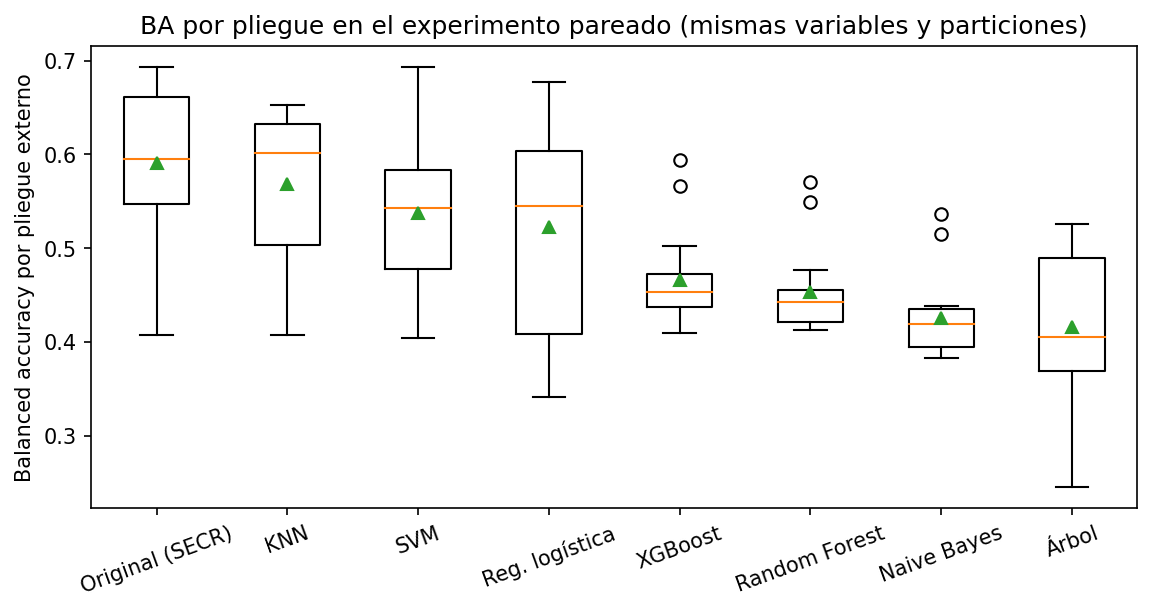

Supuestos de Nadeau-Bengio: Shapiro-Wilk sobre las diferencias, p = 0.049
IC BCa 95 % de la diferencia media de BA (original − mejor): [-0.0317  0.0563]
δ de Cliff [IC 95 %]: [ 0.191 -0.138  0.538]


In [6]:
display(Image('figures/e3_ba_pliegues_pareado.png'))
print('Supuestos de Nadeau-Bengio: Shapiro-Wilk sobre las diferencias, p =', round(res['shapiro_p'], 3))
print('IC BCa 95 % de la diferencia media de BA (original − mejor):', np.round(res['diff_ci_bca'], 4))
print('δ de Cliff [IC 95 %]:', np.round(res['cliff'], 3))

**Interpretación.**

- **Frente al mejor benchmark (KNN) ninguna prueba pareada rechaza la igualdad** después de Holm: Nemenyi
  (p ajustado 0,81), Nadeau–Bengio (t(14) = 0,45; p ajustado 0,66) y Wilcoxon (p ajustado 0,28). La diferencia media
  de BA es +0,022 con IC BCa 95 % [−0,032; 0,056], que incluye el 0. El δ de Cliff es 0,19 (pequeño), con IC
  [−0,14; 0,54]. La prueba bayesiana da 0,947 de probabilidad posterior de que el original sea mejor por más de 0,01
  de BA: cerca de 0,95, pero sin alcanzarlo.
- **Supuestos.** Las diferencias por pliegue se apartan algo de la normalidad (Shapiro p = 0,049). Por eso la
  conclusión no descansa solo en Nadeau–Bengio: Wilcoxon (sin normalidad) y la prueba bayesiana dicen lo mismo. Los
  pliegues de repeticiones distintas comparten casos, y eso es justo lo que corrige Nadeau–Bengio
  ($1/J + n_{test}/n_{train}$).
- **Frente a cada benchmark** (Wilcoxon con Holm sobre 7 comparaciones), el original es significativamente mejor que
  el árbol (p = 0,0002; δ = 0,87), Naive Bayes (p = 0,0004; δ = 0,88), Random Forest (p = 0,003; δ = 0,77) y XGBoost
  (p = 0,009; δ = 0,72), todos con efecto grande. No lo es frente a SVM (p = 0,072), la logística (p = 0,072) ni KNN
  (p = 0,094).
- **Por qué no alcanza.** La BA de 4 clases depende de acertar a los fallecimientos: hay 0 a 4 por pliegue, y acertar
  uno solo mueve la BA ±0,25 (pliegue 1 de la repetición 0: KNN 0,625 frente a 0,407 del original, con un solo
  fallecimiento). Esa varianza entre pliegues (d.e. 0,08–0,09) es cuatro veces la ventaja media (0,022). Con este
  tamaño de efecto harían falta muchos más pliegues para detectarla (del orden de 60 a 100 según la potencia de
  Wilcoxon), y el presupuesto de cómputo de esta corrida no lo permitió.

## 20.4 Ablación: ¿qué aporta cada componente?

Mismos modelos base, mismas predicciones y mismos 15 pliegues. Se retira un componente cada vez, o la regla de
combinación se reemplaza por una regla estándar (Cuadro 1 de la guía: promedio simple, pesos por error global,
stacking lineal). La columna «p (Holm)» es el Wilcoxon unilateral de «SECR completo es mejor que la variante».

In [7]:
a = pd.DataFrame(res['ablation'])
a.round(4)

,variante,ba_mean,ba_sd,log_loss,diff_vs_original,p_wilcoxon,p_holm
0,SECR completo (original),0.5912,0.0869,0.8428,-0.0000,NaN,NaN
1,SECR sin regiones (solo pesos globales),0.5803,0.0965,0.8428,-0.0109,0.7032,1.0000
2,SECR sin corrección por prior (α = 0),0.4641,0.0499,0.8428,-0.1271,0.0013,0.0092
3,Caruana global (modelo G),0.5983,0.0869,0.8426,0.0071,0.9760,1.0000
4,Stacking lineal (logística multinomial),0.5232,0.0983,0.8485,-0.0680,0.0603,0.2411
5,Pesos por error global,0.5784,0.1055,0.8716,-0.0128,0.0473,0.2365
6,Promedio simple,0.5684,0.1003,0.8757,-0.0228,0.0062,0.0374
7,Mejor modelo base individual,0.5917,0.1010,0.8483,0.0005,0.7556,1.0000


**Interpretación (honesta) de la ablación.**

- **La corrección por prior es el componente que más aporta**: quitarla baja la BA de 0,591 a 0,464 (Wilcoxon con
  Holm p = 0,009). La log-loss no cambia, porque la decisión no altera las probabilidades.
- **Las regiones no aportan en BA**: SECR sin regiones da 0,580 (p = 1,0) y Caruana global 0,598, sin diferencia
  significativa con SECR completo. La búsqueda TPE eligió una compuerta en 14 de 15 pliegues, pero cambia de un pliegue a
  otro (sector, tipo de establecimiento, tipo de incidente, naturaleza o evento) y λ va de 1 a 8 311: no hay una
  estructura regional estable que aprovechar. **El mecanismo nuevo de SECR no mejoró la métrica
  principal en este problema**: con estas vistas, la calidad relativa de los modelos base es parecida entre regiones.
- **Frente a las reglas estándar**: SECR supera de forma significativa al promedio simple (p = 0,037 con Holm). Frente
  a los pesos por error global (p = 0,24) y al stacking lineal (p = 0,24) gana en media (+0,013 y +0,068) sin
  significancia tras Holm. El stacking lineal tiene peor log-loss (0,849) y peor BA (0,523).

## 20.5 Convergencia de Frank-Wolfe

La curva muestra la log-loss fuera de pliegue y la brecha de Frank-Wolfe por iteración (pesos globales,
repetición 0, pliegue 0). La pérdida nunca sube (proposición 2) y la brecha, que acota la distancia al óptimo
(proposición 3), cae varios órdenes de magnitud.

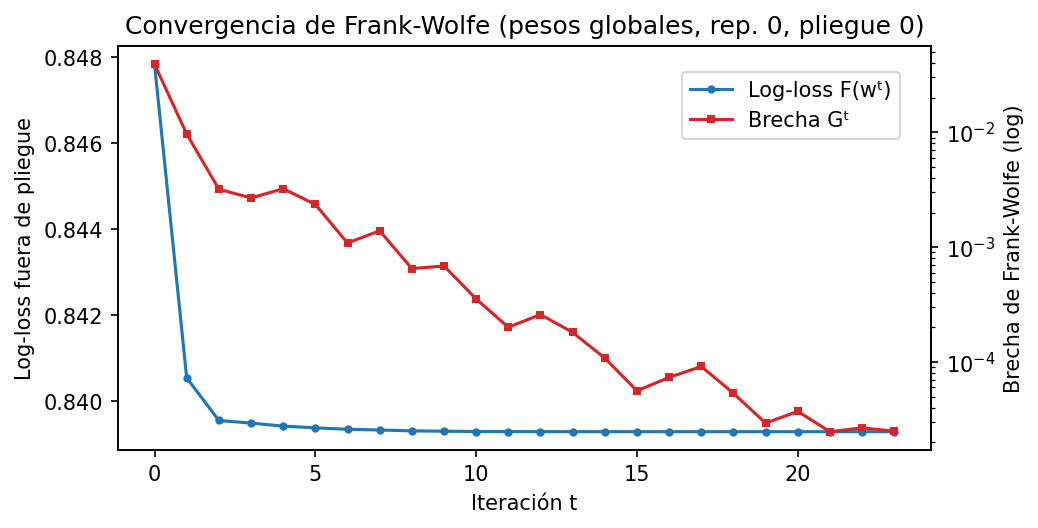

In [8]:
display(Image('figures/e3_convergencia_fw.png'))

La pérdida baja de forma monótona en todas las iteraciones (proposición 2). La brecha de Frank-Wolfe cae varios
órdenes de magnitud y, por la proposición 3, certifica que la solución está a menos de esa brecha del óptimo.

## 20.6 Veredicto

In [9]:
display(Markdown('> **' + res['verdict'] + '**'))

> **Veredicto R3: NO SUPERIOR. BA media del original 0.591 frente a 0.569 del mejor benchmark pareado (KNN); 1 de 4 pruebas frecuentistas rechazan H0 con p ajustado por Holm < 0,05 (la global de Friedman sí); δ de Cliff = 0.191 (pequeño). Media mayor que la de los 7 benchmarks: sí.**

**Lectura del veredicto según la guía (§6.1 y §12.1).**

| Condición de superioridad | ¿Se cumple? | Evidencia |
|---|---|---|
| 1. BA media mayor que la del mejor benchmark y que la de cada uno de los 7 | **Sí** | 0,591 frente a 0,569 (KNN); mayor que los 7 en las celdas comunes y en la repetición 0 |
| 2. Al menos 3 pruebas con p ajustado < 0,05, una de ellas global | **No** | Solo Friedman (global) rechaza; Nemenyi, Nadeau–Bengio y Wilcoxon frente a KNN no |
| 3. Tamaño del efecto no despreciable (|δ| ≥ 0,147) | **Sí** (pequeño) | δ = 0,19, pero su IC incluye el 0 |

**Sesgo de selección (declarado).** La BA de 0,591 es **optimista**, por dos razones:

- el original salió de elegir entre varios candidatos (sección 19.9: 5 diseños del capítulo 17 y 7 variantes del 18);
- su nivel 0 (G) se eligió mirando los 5 pliegues de los capítulos 6 a 13, que son la repetición 0 de este capítulo
  (`paired.outer_folds(0)`).

Se nota en las cifras: la ventaja sobre KNN es +0,035 en la repetición 0 (pliegues ya vistos) y +0,006 y +0,027 en las
repeticiones 1 y 2 (no vistos). El sesgo va **a favor** del original, así que concluir «R3 = no» es conservador: sin
ese sesgo, la ventaja sería igual o menor.

Como la condición 2 falla, **R3 no se cumple**: el modelo original es el mejor en media y en rango, pero no es
superior de forma estadísticamente significativa al mejor benchmark pareado. Con R1 y R2 cumplidos (capítulos 16 y
19), el tope que corresponde es **4,0** (guía §12.1). Se reporta así aunque sea desfavorable. Lo que no se hizo:
repetir la corrida con más repeticiones, otra semilla u otra métrica después de ver estos resultados, porque eso sería
buscar la significancia (guía §13).

## 20.7 Sensibilidad y robustez (descriptivo)

Para ver cómo responde SECR a sus hiperparámetros y a tener menos datos, se fija una configuración base (compuerta =
sector NAICS-2, λ = 100, 30 pasos, región mínima = 200, α = 1) y se cambia **un** valor cada vez. Para robustez a menor
tamaño de muestra, los pesos se ajustan con el 10 %, 25 %, 50 % o 100 % de las predicciones internas. Todo se mide en
los mismos pliegues externos. **Es un análisis descriptivo**: no se usa para elegir nada (eso lo hizo la TPE interna) y
mirar estas cifras para escoger la configuración sería usar los pliegues externos para ajustar.

In [10]:
sens = pd.read_csv(R / 'sensibilidad_secr.csv')
sens.groupby(['param', 'value'])[['ba', 'log_loss']].agg(['mean', 'std']).round(4)

ba         log_loss        
                                 mean     std     mean     std
param      value                                              
alpha      0.0                 0.4625  0.0500   0.8427  0.0457
           0.25                0.4638  0.0504   0.8427  0.0457
           0.5                 0.4695  0.0528   0.8427  0.0457
           0.75                0.5407  0.1017   0.8427  0.0457
           1.0                 0.5851  0.0762   0.8427  0.0457
frac_datos 0.1                 0.3092  0.1997   0.8441  0.0452
           0.25                0.5265  0.1180   0.8431  0.0460
           0.5                 0.5738  0.0953   0.8431  0.0455
           1.0                 0.5851  0.0762   0.8427  0.0457
gate       establishment_type  0.6009  0.0695   0.8432  0.0460
           event1              0.5945  0.0760   0.8434  0.0464
           naics2              0.5851  0.0762   0.8427  0.0457
           nature1             0.6159  0.0523   0.8428  0.0455
           none                0.6178  0.0506   0.8426  0.0459
           part1               0.6163  0.0508   0.8433  0.0459
           soc2                0.6159  0.0509   0.8432  0.0454
           type_of_incident    0.6182  0.0538   0.8428  0.0459
lam        1.0                 0.5850  0.0765   0.8431  0.0457
           10.0                0.5849  0.0765   0.8430  0.0457
           100.0               0.5851  0.0762   0.8427  0.0457
           1000.0              0.6125  0.0518   0.8419  0.0458
           10000.0             0.6181  0.0496   0.8420  0.0459
n_steps    10                  0.5906  0.0764   0.8426  0.0457
           100                 0.5854  0.0763   0.8428  0.0457
           30                  0.5851  0.0762   0.8427  0.0457
           5                   0.6010  0.0762   0.8427  0.0460

**Interpretación.**

- **α es el hiperparámetro decisivo.** Con α ≤ 0,5 la BA queda en ~0,46; con α = 1 sube a ~0,59. La log-loss no cambia,
  porque α solo mueve la decisión.
- **λ, los pasos y la compuerta casi no cambian la log-loss** (0,842–0,843). En BA, las configuraciones que se acercan a
  pesos globales (sin compuerta, o con λ ≥ 1000) dan ~0,62. Es **más** que el 0,591 del modelo con TPE: la búsqueda
  interna, con 3 pliegues y una BA tan ruidosa, elige compuertas y λ que no generalizan (costo de la selección). Este
  hallazgo es descriptivo y **no se usa para cambiar el modelo**, porque elegir con los pliegues externos invalidaría
  la comparación. Queda como lección para el trabajo futuro: la versión global, más simple, habría sido una mejor
  apuesta *a priori* en este problema.
- **Robustez a menos datos.** Con el 50 % de las predicciones internas la BA baja poco (0,574); con el 25 % baja a 0,527.
  Con el 10 % el método se vuelve inestable (0,309 ± 0,200): las regiones y α se estiman con muy pocos fallecimientos.

## 20.8 Interpretabilidad: SHAP del original frente al mejor benchmark

Valores de Shapley exactos por **grupos de variables** (`dashboard_final/src/explain.py`), calculados sobre los mismos
casos del desarrollo para el modelo original y para la mejor combinación del curso (SVM + SMOTE, 9 variables). Se
reporta el |SHAP| medio de la probabilidad de la clase predicha. Un grupo que un modelo no usa tiene aporte 0.

,Original (SECR),SVM + SMOTE (mejor del curso)
Naturaleza de la lesión,0.1038,0.0000
Evento y fuente,0.0784,0.0000
Estado,0.0650,0.0184
Empleador,0.0577,0.0000
Actividad (NAICS),0.0495,0.1155
Parte del cuerpo,0.0370,0.0000
Ocupación (SOC),0.0176,0.0497
Horario,0.0116,0.0184
Tipo de establecimiento,0.0046,0.0039
Tipo de incidente,0.0038,0.0114


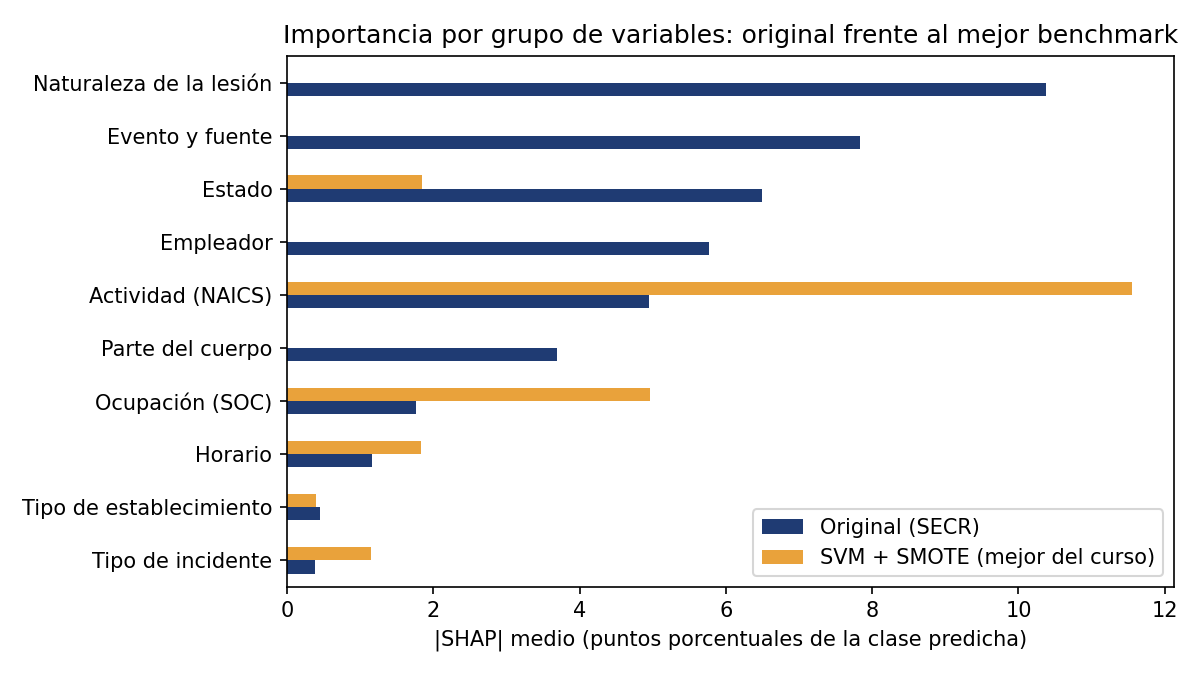

In [11]:
shp = R / 'shap_original_vs_benchmark.csv'
if shp.exists():
    display(pd.read_csv(shp, index_col=0).round(4))
    display(Image('figures/e3_shap_original_vs_benchmark.png'))